# 03 Inputs and importance: how few measurements are enough, and which ones the trained network relies on

**Question (REQ-004).** How does the agreement with the reference reconstruction fall when fewer of the 24 magnetic measurements (16 coils `IPR01-16`, 8 flux loops `FL01-08`) are used, and which inputs does the trained network rely on? The ranking describes the trained network, not the information content of a sensor.

The expensive part (network retrained for every subset on 5 folds by discharge) was run once by
`analysis/ipp1_inputs.py` and saved in `out/ipp1-inputs.json`; this notebook reads and plots it. To check the findings
independently it then re-runs a light version with a **ridge** model (seconds), with the ranking recomputed on the
training rows of every fold so the test discharges never influence which inputs are kept.

Runtime: under 1 minute (8 s measured, 2 CPU threads); needs the raw data and `out/ipp1-inputs.json` (made by `analysis/ipp1_inputs.py`, about 1 h, or `python analysis/make_all.py --quick`, which copies `results/ipp1-inputs.json`); `scipy` is used in section 3.

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository")
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Saved network results

In [2]:
saved = json.load(open(C.OUT / "ipp1-inputs.json"))
KEY = {"saved_folds": saved["folds"], "saved_epochs": saved["epochs"]}
runs = saved["runs"]
order = ["all 24"] + [k for k in runs if k.startswith("top")] + ["IPR only (16)", "FL only (8)"]
base = runs["all 24"]["summary_nrmse_mean"]
rows = [dict(inputs=n, summary_nrmse=runs[n]["summary_nrmse_mean"], std_over_folds=runs[n]["summary_nrmse_std"], ratio_to_all_24=runs[n]["summary_nrmse_mean"] / base) for n in order]
tab = pd.DataFrame(rows).set_index("inputs")
print("summary error = mean nRMSE over the 13 targets without the limiter point and is_limited (lower is better)")
print(tab.round(4).to_string())
KEY["mlp_summary_nrmse"] = {n: round(runs[n]["summary_nrmse_mean"], 4) for n in order}
KEY["mlp_summary_nrmse_fold_std"] = {n: round(runs[n]["summary_nrmse_std"], 4) for n in order}
KEY["mlp_ratio_to_all_24"] = {n: round(runs[n]["summary_nrmse_mean"] / base, 3) for n in order}
KEY["ranking_mlp"] = saved["ranking"]
names = saved["inputs"]
imp = np.array([saved["permutation_importance"][n] for n in names])
ks = [24] + [int(k.split()[1]) for k in order if k.startswith("top")]
vals = [runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_mean"] for k in ks]
errs = [runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_std"] for k in ks]

summary error = mean nRMSE over the 13 targets without the limiter point and is_limited (lower is better)
               summary_nrmse  std_over_folds  ratio_to_all_24
inputs                                                       
all 24                0.0633          0.0282           1.0000
top 16                0.0667          0.0217           1.0541
top 12                0.0775          0.0236           1.2246
top 8                 0.0943          0.0219           1.4905
top 6                 0.1429          0.0535           2.2582
top 5                 0.1565          0.0610           2.4742
top 4                 0.2036          0.0737           3.2178
top 3                 0.2647          0.0834           4.1850
top 2                 0.4036          0.0686           6.3802
IPR only (16)         0.0657          0.0316           1.0392
FL only (8)           0.2852          0.0533           4.5081


Per-target errors in physical units for some of the subsets:

In [3]:
cols = ["all 24", "top 12", "top 8", "top 6", "top 4", "IPR only (16)", "FL only (8)"]
rows = []
for t in runs["all 24"]["targets"]:
    rows.append({"target": t, "unit": runs["all 24"]["targets"][t]["unit"] or "-", **{c: runs[c]["targets"][t]["mae"] for c in cols}})
print("MAE in the unit shown, network trained on the listed inputs")
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
KEY["mlp_mae_by_subset"] = {t: {c: round(runs[c]["targets"][t]["mae"], 4) for c in cols} for t in runs["all 24"]["targets"]}

MAE in the unit shown, network trained on the listed inputs
                 unit   all 24   top 12    top 8    top 6    top 4  IPR only (16)  FL only (8)
target                                                                                        
plasma_current     kA   1.4883   1.5068   1.4814   2.0794   2.9062         1.2768       6.5659
R_mag_axis         mm   0.3772   0.6290   0.9036   1.6168   2.4321         0.4918       2.3194
Z_mag_axis         mm   0.3915   0.6622   1.1689   1.5805   2.3311         0.4014       1.7160
elongation          -   0.0057   0.0063   0.0066   0.0088   0.0136         0.0055       0.0203
R_x_point          mm   0.2024   0.2673   0.4570   0.9807   1.6250         0.2838       1.4894
R_strike_point_1   mm   0.2646   0.2205   0.2629   0.8137   1.6883         0.3438       3.0254
R_limiter          mm  10.7303  11.7300  13.5058  17.0122  17.9937        12.2517      21.9421


## 2. Figures from the saved results

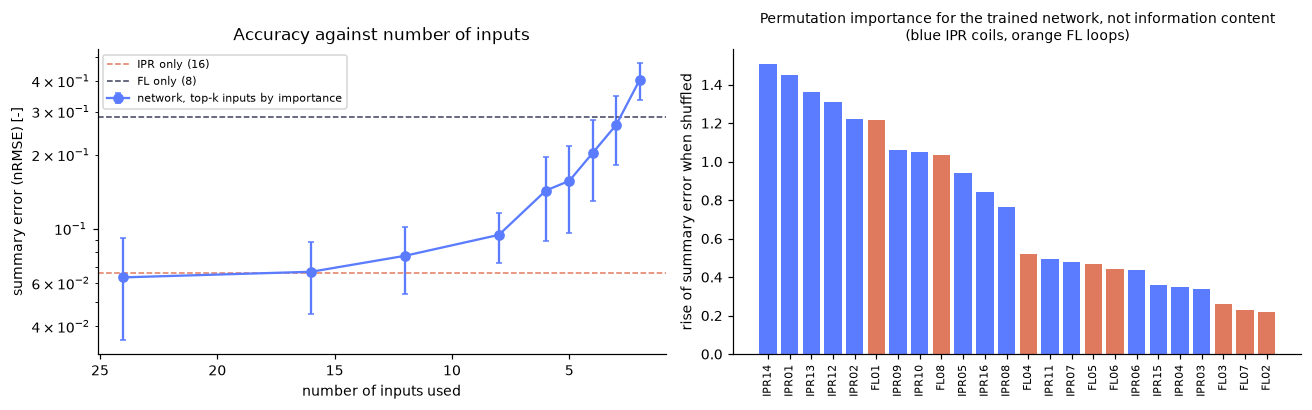

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].errorbar(ks, vals, yerr=errs, marker="o", color="#5b7cff", capsize=2, label="network, top-k inputs by importance")
for n, c in (("IPR only (16)", "#e07a5f"), ("FL only (8)", "#3d405b")):
    ax[0].axhline(runs[n]["summary_nrmse_mean"], color=c, ls="--", lw=1, label=n)
ax[0].set_yscale("log"); ax[0].set_xlabel("number of inputs used"); ax[0].set_ylabel("summary error (nRMSE) [-]")
ax[0].invert_xaxis(); ax[0].legend(fontsize=7); ax[0].set_title("Accuracy against number of inputs")
o = np.argsort(-imp)
ax[1].bar(range(24), imp[o], color=["#e07a5f" if names[i].startswith("FL") else "#5b7cff" for i in o])
ax[1].set_xticks(range(24)); ax[1].set_xticklabels([names[i] for i in o], rotation=90, fontsize=7)
ax[1].set_title("Permutation importance for the trained network, not information content\n(blue IPR coils, orange FL loops)", fontsize=9); ax[1].set_ylabel("rise of summary error when shuffled")
fig.tight_layout(); plt.show()

## 3. Independent light check with a linear model

For every fold: fit ridge on the training discharges, rank the inputs by permutation importance on a sample of the
**training** rows, then refit ridge on the top-k inputs and score it on the held-out discharges. We also try
a projection on the first k principal components (this still needs all 24 sensors; it only shows how the error behaves when the inputs are reduced to their first k variance directions).

In [5]:
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

df, X, Y, G, M = C.load()
folds = C.group_folds(X, Y, G, 5)
SUMMARY = [t for t in C.TARGETS if t not in ("R_limiter", "Z_limiter", "is_limited")]
summ = lambda res: float(np.mean([res[t]["nrmse"] for t in SUMMARY]))
K_LIST = [24, 16, 12, 8, 6, 5, 4, 3, 2]
rng = np.random.default_rng(0)
ridge_curve = {k: [] for k in K_LIST}
pc_curve = {k: [] for k in (1, 2, 3, 4, 5, 6, 8, 12, 24)}
fold_imp = np.zeros((5, 24))
ipr = [i for i, c in enumerate(names) if c.startswith("IPR")]
fl = [i for i, c in enumerate(names) if c.startswith("FL")]
group_runs = {"IPR only (16)": [], "FL only (8)": []}
t0 = time.time()
for f, (tr, te) in enumerate(folds):
    model = C.fit_ridge(X[tr], Y[tr], M[tr])
    sub = rng.choice(tr, size=min(6000, len(tr)), replace=False)
    b0 = summ(C.score(model(X[sub]), Y[sub], M[sub]))
    for j in range(24):
        xp = X[sub].copy()
        xp[:, j] = rng.permutation(xp[:, j])
        fold_imp[f, j] = summ(C.score(model(xp), Y[sub], M[sub])) - b0
    rank = np.argsort(-fold_imp[f])
    for k in K_LIST:
        cols_k = np.sort(rank[:k])
        m = C.fit_ridge(X[tr][:, cols_k], Y[tr], M[tr])
        ridge_curve[k].append(summ(C.score(m(X[te][:, cols_k]), Y[te], M[te])))
    for name, cols_g in (("IPR only (16)", ipr), ("FL only (8)", fl)):
        m = C.fit_ridge(X[tr][:, cols_g], Y[tr], M[tr])
        group_runs[name].append(summ(C.score(m(X[te][:, cols_g]), Y[te], M[te])))
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
    pca = PCA(24).fit((X[tr] - mu) / sd)
    ztr, zte = pca.transform((X[tr] - mu) / sd), pca.transform((X[te] - mu) / sd)
    for k in pc_curve:
        m = C.fit_ridge(ztr[:, :k].astype(np.float32), Y[tr], M[tr])
        pc_curve[k].append(summ(C.score(m(zte[:, :k].astype(np.float32)), Y[te], M[te])))
print(f"light ridge study done in {time.time() - t0:.0f} s")

rows = [dict(inputs=("all 24" if k == 24 else f"top {k}"), ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for k, v in ridge_curve.items()]
rows += [dict(inputs=n, ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for n, v in group_runs.items()]
rows += [dict(inputs=f"{k} principal components", ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for k, v in pc_curve.items()]
rt = pd.DataFrame(rows).set_index("inputs")
print(rt.round(4).to_string())
KEY["ridge_summary_nrmse"] = {r: round(float(v), 4) for r, v in rt.ridge_summary_nrmse.items()}

light ridge study done in 3 s
                         ridge_summary_nrmse  std_over_folds  ratio_to_all_24
inputs                                                                       
all 24                                0.4630          0.0883           1.0000
top 16                                0.4673          0.0890           1.0095
top 12                                0.4694          0.0829           1.0138
top 8                                 0.4951          0.0840           1.0693
top 6                                 0.5630          0.0514           1.2161
top 5                                 0.6039          0.0729           1.3045
top 4                                 0.6388          0.0777           1.3799
top 3                                 0.7294          0.0589           1.5754
top 2                                 0.8442          0.0324           1.8236
IPR only (16)                         0.4668          0.0885           1.0084
FL only (8)                       

### Is the ranking stable, and does the linear model agree with the network?

In [6]:
imp_ridge = fold_imp.mean(0)
pair = [spearmanr(fold_imp[a], fold_imp[b]).statistic for a in range(5) for b in range(a + 1, 5)]
KEY["ridge_ranking_fold_to_fold_spearman_mean"] = float(np.mean(pair))
KEY["ridge_ranking_fold_to_fold_spearman_min"] = float(np.min(pair))
sp = spearmanr(imp, imp_ridge)
KEY["spearman_mlp_vs_ridge_importance"] = float(sp.statistic)
top_r = [names[i] for i in np.argsort(-imp_ridge)]
KEY["ranking_ridge"] = top_r
overlap = {k: len(set(saved["ranking"][:k]) & set(top_r[:k])) for k in (4, 6, 8, 12)}
KEY["top_k_overlap_mlp_ridge"] = overlap
print(f"ridge ranking, fold to fold Spearman: mean {np.mean(pair):.3f}, min {np.min(pair):.3f}")
print(f"Spearman between network importance and ridge importance: {sp.statistic:.3f}")
print("top inputs, network:", saved["ranking"][:8])
print("top inputs, ridge  :", top_r[:8])
print("overlap of the top-k sets (network vs ridge):", overlap)

ridge ranking, fold to fold Spearman: mean 0.857, min 0.788
Spearman between network importance and ridge importance: 0.460
top inputs, network: ['IPR14', 'IPR01', 'IPR13', 'IPR12', 'IPR02', 'FL01', 'IPR09', 'IPR10']
top inputs, ridge  : ['IPR09', 'IPR02', 'IPR04', 'IPR05', 'IPR01', 'FL08', 'IPR13', 'IPR11']
overlap of the top-k sets (network vs ridge): {4: 0, 6: 2, 8: 4, 12: 8}


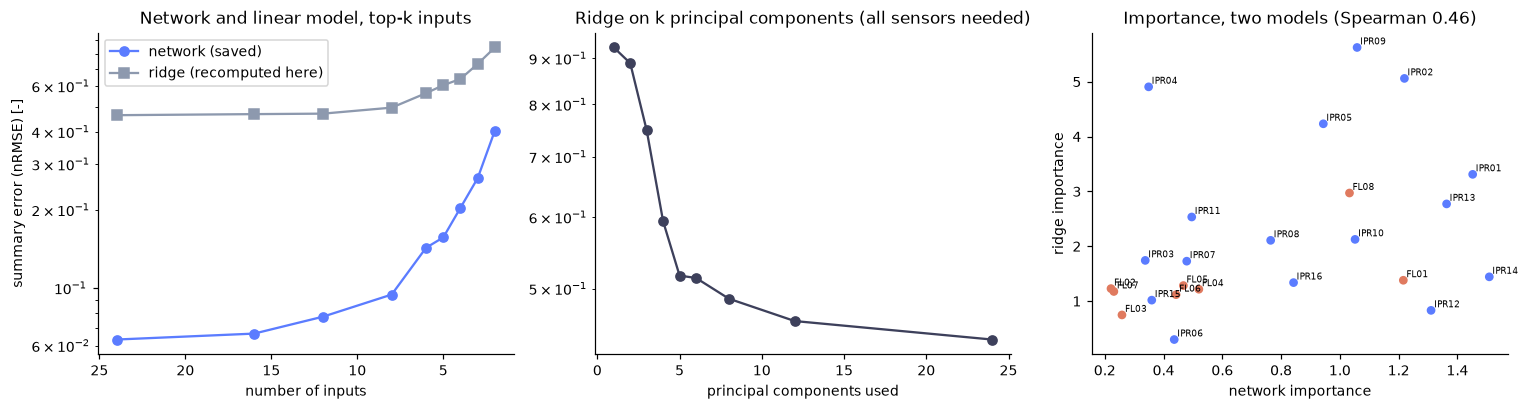

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
kk = [24] + K_LIST[1:]
ax[0].plot(ks, vals, marker="o", color="#5b7cff", label="network (saved)")
ax[0].plot(kk, [np.mean(ridge_curve[k]) for k in kk], marker="s", color="#8d99ae", label="ridge (recomputed here)")
ax[0].set_yscale("log"); ax[0].invert_xaxis(); ax[0].set_xlabel("number of inputs"); ax[0].set_ylabel("summary error (nRMSE) [-]"); ax[0].legend()
ax[0].set_title("Network and linear model, top-k inputs")
pcs = list(pc_curve)
ax[1].plot(pcs, [np.mean(pc_curve[k]) for k in pcs], marker="o", color="#3d405b")
ax[1].set_yscale("log"); ax[1].set_xlabel("principal components used"); ax[1].set_title("Ridge on k principal components (all sensors needed)")
ax[2].scatter(imp, imp_ridge, c=["#e07a5f" if n.startswith("FL") else "#5b7cff" for n in names], s=22)
for n, a, b in zip(names, imp, imp_ridge):
    ax[2].annotate(n, (a, b), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax[2].set_xlabel("network importance"); ax[2].set_ylabel("ridge importance"); ax[2].set_title(f"Importance, two models (Spearman {sp.statistic:.2f})")
fig.tight_layout(); plt.show()

## 4. How few inputs are enough?

We read off the smallest k for which the network stays within a chosen factor of the all-24 error.

In [8]:
elbow = {}
for factor in (1.25, 1.5, 2.0):
    ok = [k for k in ks if runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_mean"] <= factor * base]
    elbow[str(factor)] = int(min(ok))
KEY["smallest_k_within_factor_of_all_24"] = elbow
print("smallest number of inputs whose network error is within a factor of the all-24 error:", elbow)

smallest number of inputs whose network error is within a factor of the all-24 error: {'1.25': 12, '1.5': 8, '2.0': 8}


## 4b. Controls and retraining rankings

The permutation ranking above is checked against subsets chosen in other ways, each inside the training discharges of every fold (`results/ipp1-inputs-controls.md`), and against two retraining rankings (`results/ipp1-inputs-ranking.md`).

In [9]:
ctrl = json.load(open(repo / "results" / "ipp1-inputs-controls.json"))
print(f"{len(ctrl['folds_run'])} folds, {ctrl['epochs']} epochs; summary nRMSE (mean over folds, lower is better)")
for name, r in ctrl["runs"].items():
    print(f"  {name:28s} {r['summary_nrmse_mean']:.4f} +- {r['summary_nrmse_std']:.4f}")

5 folds, 60 epochs; summary nRMSE (mean over folds, lower is better)
  all 24                       0.0633 +- 0.0282
  permutation top 12           0.0775 +- 0.0236
  random (mean of 3 draws) 12  0.0995 +- 0.0259
  QR-pivot 12                  0.0648 +- 0.0298
  backward ridge 12            0.0728 +- 0.0287
  permutation top 8            0.1150 +- 0.0515
  random (mean of 3 draws) 8   0.1513 +- 0.0632
  QR-pivot 8                   0.0717 +- 0.0306
  backward ridge 8             0.0869 +- 0.0280
  permutation top 6            0.1429 +- 0.0535
  random (mean of 3 draws) 6   0.2139 +- 0.0466
  QR-pivot 6                   0.1262 +- 0.0235
  backward ridge 6             0.1161 +- 0.0204


### 4c. The numbers behind REQ-004, parsed from the committed results

This cell group reads `results/ipp1-inputs-ranking.md` (retraining rankings on the 119 development discharges, 5 folds, 3 seeds for the noise estimate) and `results/ipp1-inputs-controls.json` (subsets chosen in other ways, inside the training discharges of every fold, one seed per cell) and checks them against the numbers quoted in the conclusions, so the text cannot drift from the files.

In [10]:
import re
rk = (repo / "results" / "ipp1-inputs-ranking.md").read_text()
seed_noise = float(re.search(r"by ([\d.]+)% on average", rk).group(1))
drop_txt = rk.split("## Drop-column ranking")[1].split("## Backward-elimination order")[0]
drop = pd.DataFrame([(int(a), b, float(c), float(d), int(e)) for a, b, c, d, e in re.findall(r"\| (\d+) \| ((?:IPR|FL)\d\d) \| ([+-][\d.]+) \| ([+-][\d.]+)% \| [\d.]+ \| (\d)/5 \|", drop_txt)],
                    columns=["rank", "input", "delta", "rel_%", "folds_worse"])
be_txt = rk.split("## Backward-elimination order")[1].split("### Ridge summary error")[0]
be = pd.DataFrame([(int(a), b, float(c), [int(v) for v in d.split(",")]) for a, b, c, d in re.findall(r"\| (\d+) \| ((?:IPR|FL)\d\d) \| ([\d.]+) \| ([\d, ]+) \|", be_txt)],
                  columns=["rank", "input", "mean_step", "per_fold"])
rank_corr = {a: float(b) for a, b in re.findall(r"\| ((?:drop column|ridge) vs (?:ridge|permutation)) \| ([+-][\d.]+) \|", rk)}
assert len(drop) == 24 and len(be) == 24 and len(rank_corr) == 3, "the ranking file changed format"
print(f"Seed noise of the all-24 network (refits with 3 seeds per fold): {seed_noise} % of the summary error on average")
print("\nDrop-column ranking (network retrained without one input), five largest rises of the summary error:")
print(drop.head(5).to_string(index=False))
worse_all = drop[(drop.folds_worse == 5) & (drop["rel_%"] > seed_noise)].input.tolist()
print("\nInputs that got worse in all 5 folds AND by more than the seed noise:", worse_all)
survivors = be[be.per_fold.apply(lambda v: all(s == 24 for s in v))].input.tolist()
print("Inputs that are the last survivor of backward elimination in all 5 folds:", survivors)
print("\nRank correlation between the three orders:", rank_corr)

ctrl_runs = json.load(open(repo / "results" / "ipp1-inputs-controls.json"))["runs"]
tbl = pd.DataFrame({n: [r["summary_nrmse_mean"], r["summary_nrmse_std"]] for n, r in ctrl_runs.items()}, index=["summary nRMSE", "SD over folds"]).T
print("\nSummary error by how the subset was chosen (mean over 5 folds, one seed per cell; lower is better):")
print(tbl.round(3).to_string())
quoted = {"all 24": 0.063, "permutation top 12": 0.077, "random (mean of 3 draws) 12": 0.099, "QR-pivot 12": 0.065, "permutation top 8": 0.115, "QR-pivot 8": 0.072}
for n, v in quoted.items():
    assert round(ctrl_runs[n]["summary_nrmse_mean"], 3) == v, (n, ctrl_runs[n]["summary_nrmse_mean"], v)
assert seed_noise == 4.5 and rank_corr == {"drop column vs ridge": -0.14, "drop column vs permutation": 0.28, "ridge vs permutation": 0.40}
assert survivors == ["IPR13"] and worse_all == ["FL01"]
KEY["controls_and_ranking"] = {"seed_noise_pct": seed_noise, "rank_correlation": rank_corr, "survivors": survivors, "worse_in_all_folds_beyond_noise": worse_all}
print("\nProtocol: network (60 epochs) retrained per subset; controls: subsets chosen on the training discharges of each fold, one seed per cell, fold SD about 40 % of the mean; rankings: 119 development discharges, 5 folds by discharge, seed noise from 3 seeds per fold.")

Seed noise of the all-24 network (refits with 3 seeds per fold): 4.5 % of the summary error on average

Drop-column ranking (network retrained without one input), five largest rises of the summary error:
 rank input   delta  rel_%  folds_worse
    1 IPR12 0.02472   36.2            4
    2 IPR13 0.01098   14.7            4
    3 IPR14 0.00895   13.3            4
    4  FL01 0.00637    7.6            5
    5  FL02 0.00535    6.6            4

Inputs that got worse in all 5 folds AND by more than the seed noise: ['FL01']
Inputs that are the last survivor of backward elimination in all 5 folds: ['IPR13']

Rank correlation between the three orders: {'drop column vs ridge': -0.14, 'drop column vs permutation': 0.28, 'ridge vs permutation': 0.4}

Summary error by how the subset was chosen (mean over 5 folds, one seed per cell; lower is better):
                             summary nRMSE  SD over folds
all 24                               0.063          0.028
permutation top 12                

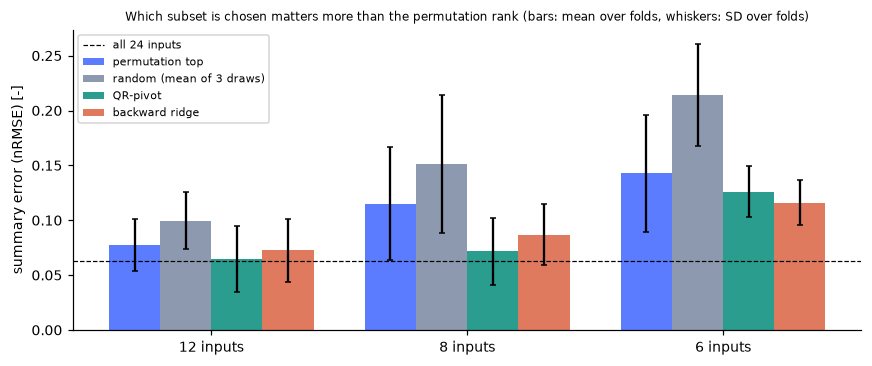

In [11]:
sizes = (12, 8, 6)
methods = [("permutation top", "#5b7cff"), ("random (mean of 3 draws)", "#8d99ae"), ("QR-pivot", "#2a9d8f"), ("backward ridge", "#e07a5f")]
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, (m, col) in enumerate(methods):
    ax.bar([i + j * 0.2 - 0.3 for i in range(len(sizes))], [ctrl_runs[f"{m} {k}"]["summary_nrmse_mean"] for k in sizes], 0.2, yerr=[ctrl_runs[f"{m} {k}"]["summary_nrmse_std"] for k in sizes], color=col, capsize=2, label=m)
ax.axhline(ctrl_runs["all 24"]["summary_nrmse_mean"], color="k", lw=0.8, ls="--", label="all 24 inputs")
ax.set_xticks(range(len(sizes))); ax.set_xticklabels([f"{k} inputs" for k in sizes]); ax.set_ylabel("summary error (nRMSE) [-]")
ax.set_title("Which subset is chosen matters more than the permutation rank (bars: mean over folds, whiskers: SD over folds)", fontsize=8); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## Conclusions

- **The 16 coils alone are almost as good as all 24 inputs.** The network trained on the 16 `IPR` coils alone has a summary error of 0.0657 against 0.0633 with all 24 inputs (1.04 times, within the seed noise), while the 8 flux loops `FL` alone give 0.2852 (4.3 times worse than the coils alone, 4.5 times worse than all 24). We do not say which sensor is the most important.
- **Which subset is chosen matters more than the permutation rank.** A QR-pivot subset of 8 inputs (0.072) beats the permutation top 8 of this control run (0.115), and a random 12 (0.099) is worse than the permutation top 12 (0.077). The three rankings we computed hardly agree (Spearman -0.14 to 0.40, `results/ipp1-inputs-ranking.md`). The only single-input statement we defend is that IPR13 survives backward elimination in all 5 folds. Note: the control run gives the permutation top 8 as 0.115, while section 4 of this notebook (a separate run, `results/ipp1-inputs.md`) gives 0.094; both are quoted with their run.
- **How few are enough.** With the inputs kept by permutation importance, the summary error is 0.0667 for 16 inputs (1.05 times), 0.0775 for 12 (1.22 times), 0.0943 for 8 (1.49 times), 0.1429 for 6 (2.26 times) and 0.2036 for 4 (3.2 times). The smallest subset that stays within 1.25 times the all-24 error has 12 inputs, and within 1.5 times has 8. Below 8 inputs the error rises quickly.
- **The loss is not the same for every target.** Going from 24 to 8 inputs raises the `R_mag_axis` error from 0.38 to 0.90 mm and `R_x_point` from 0.20 to 0.46 mm, but the plasma current stays at 1.49 and 1.48 kA and the strike point `R_strike_point_1` at 0.26 and 0.26 mm.
- **The ranking depends on the model.** The network puts IPR14, IPR01, IPR13, IPR12, IPR02 first; the ridge model, with its ranking recomputed on the training rows of each fold, puts IPR09, IPR02, IPR04, IPR05, IPR01 first. The Spearman correlation of the two importance lists is 0.46 and their top-8 sets share 4 inputs (top-4 sets share 0). Inside the ridge model the ranking is stable from fold to fold (mean Spearman 0.86, lowest 0.79). Because the inputs are so redundant, several different subsets work, so the ranking is reported as a property of the trained model, not of the sensors, and no single input is individually necessary.
- **The linear model is far weaker and loses less from fewer inputs.** Ridge with all 24 inputs has a summary error of 0.463, about 7.3 times the network, and with 8 inputs 0.495. Ridge on 5 principal components gives 0.517. A projection on principal components needs all 24 sensors, and a network on the first 5 components has a radial axis error of 2.63 mm against 0.41 mm (`results/ipp1-data-checks.md`). The table row '24 principal components' (0.439) is lower than 'all 24' (0.463) although both use all 24 sensors; the reason was not checked, so that row is not used as evidence.
- **Caveats.** The network results come from one training seed per fold (fold-to-fold standard deviation of the summary error is 0.028 for 24 inputs, see the first table), and the summary leaves out the limiter point and `is_limited`. Seed noise of the same network is 4.5 % (`results/ipp1-inputs-ranking.md`; earlier measurements 8 to 19 %), so differences below about 10 % (16 inputs, the coils alone and all 24) are not resolved.

*The conclusions above were typed from the outputs of the stored run and differ slightly after a rerun.*

**Answer.** The 16 IPR coils alone give a summary error of 0.066 against 0.063 for all 24 inputs; the 8 flux loops alone give 0.285 (4.3 times worse than the coils). Twelve inputs kept by permutation importance are within 1.22 times of all 24 and eight within 1.49 times, but which subset is chosen matters more than the rank, and the ranking is a property of the trained network, not a statement about which sensor is important.